# Homework 4: Leg Agility Filter
## Name: Jon Knapp
### Date: October 27, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown formatting
* Derivation assistance


## Problem 1: For each of the signal, show a time domain plot with the detected maxima and minima shown by dots. If you used a filter, show the filtered signal as well as the original signal on the same plot. If you applied a simple threshold (or set of thresholds) for the detection of extrema, show these thresholds on the plot.

### PSDs for provided signals

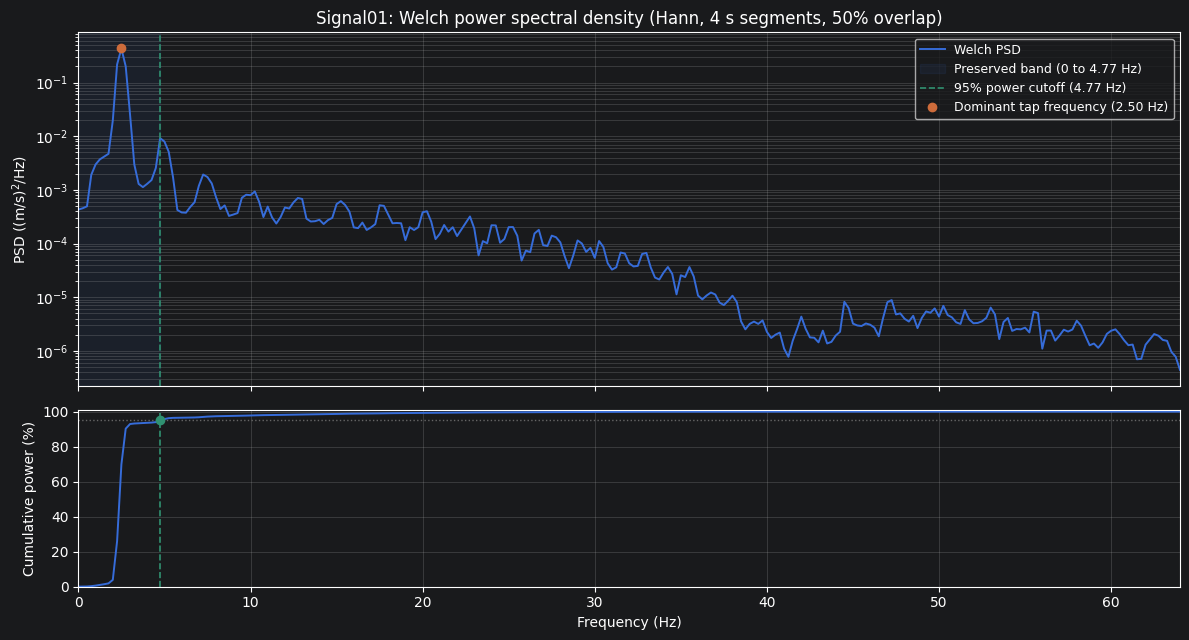

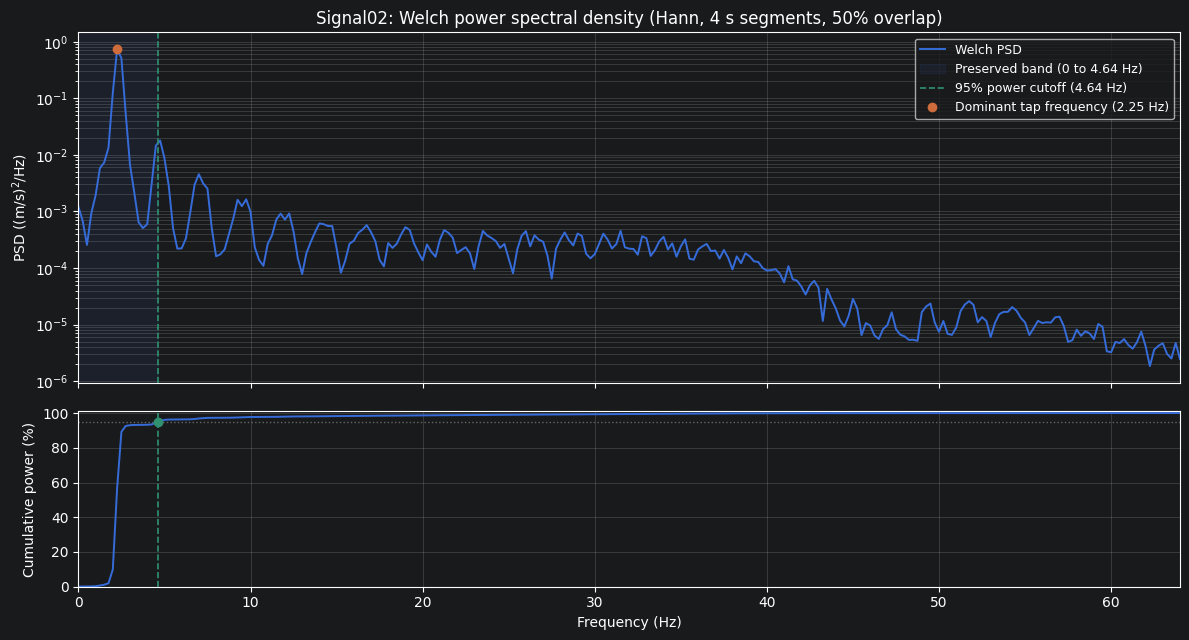

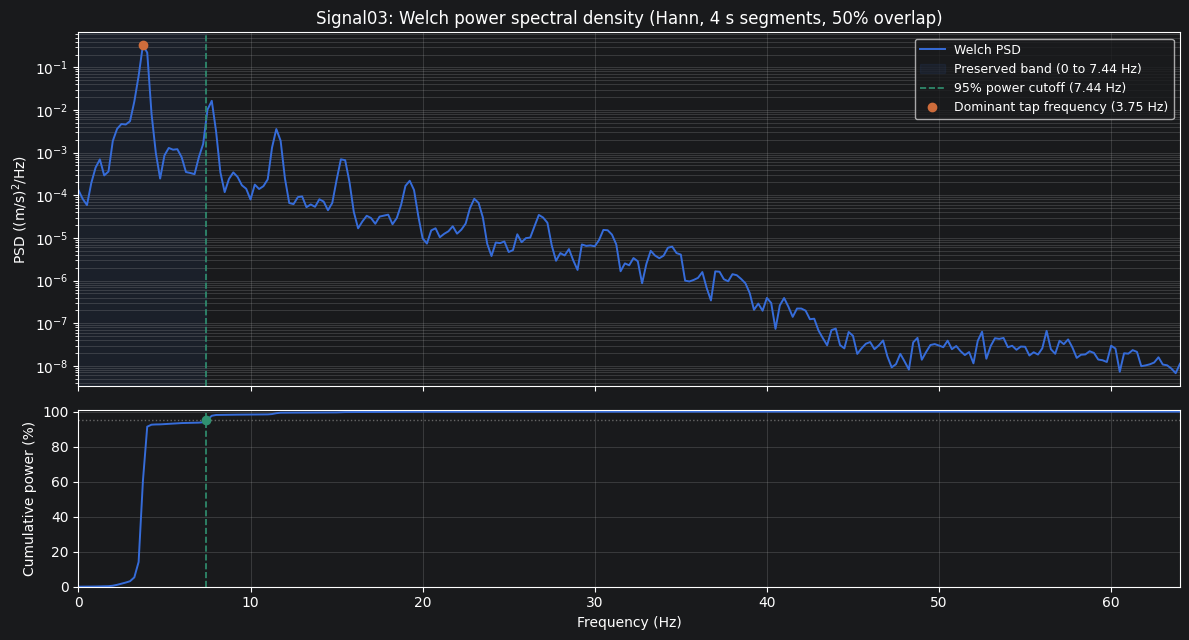

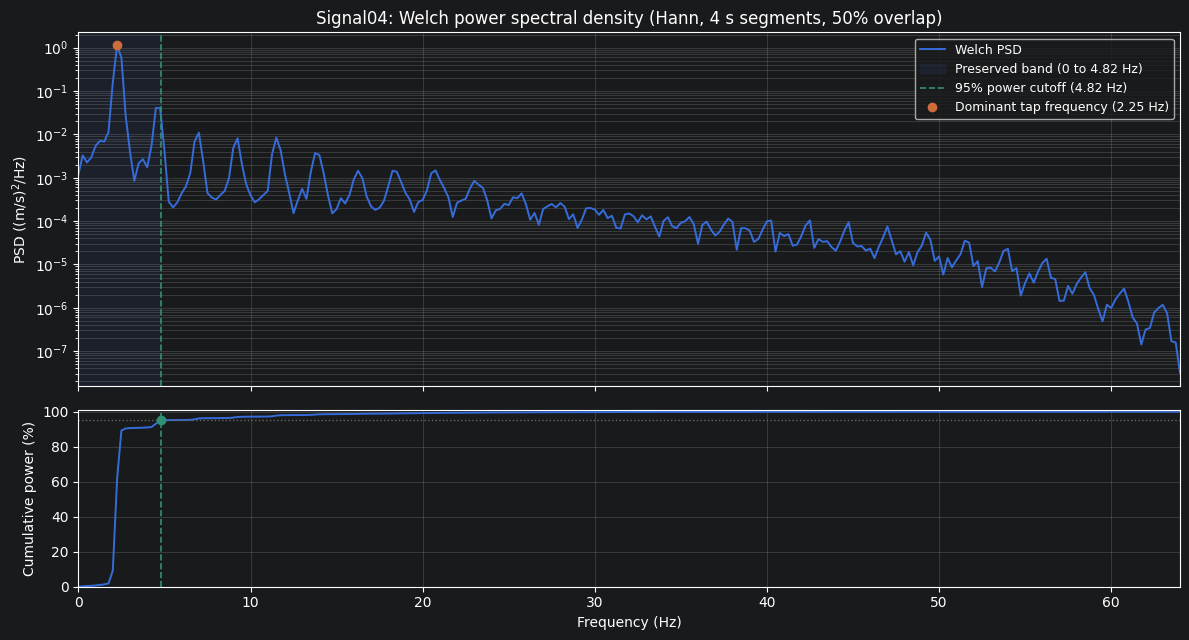

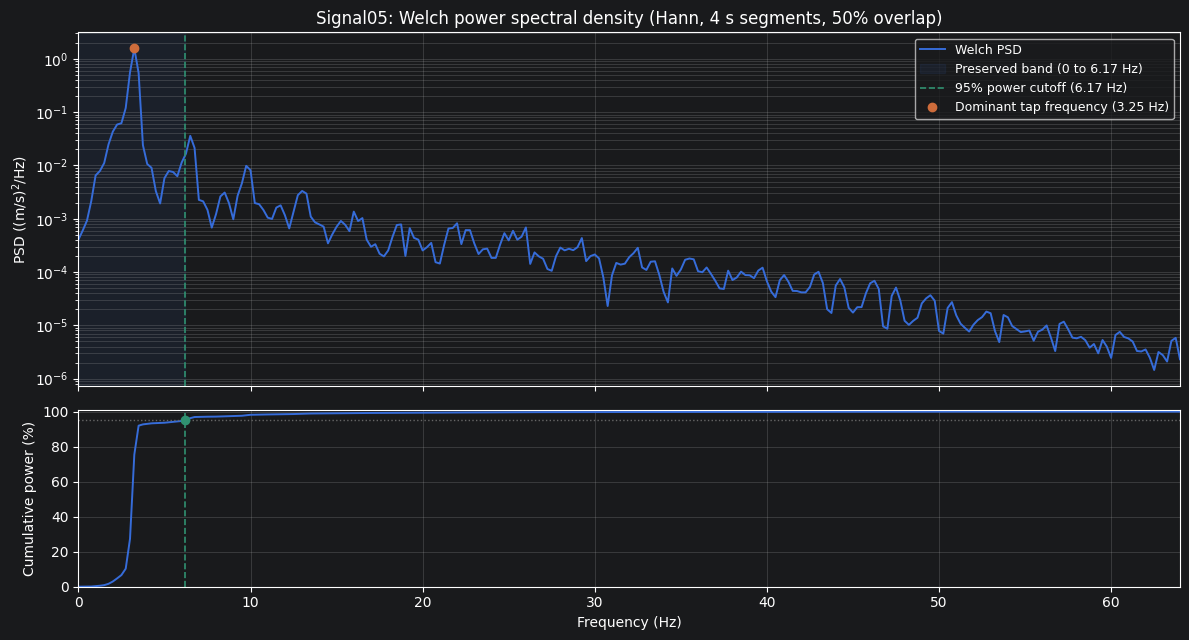

Signal       f0 (Hz)   f95 (Hz)
Signal01        2.50       4.77
Signal02        2.25       4.64
Signal03        3.75       7.44
Signal04        2.25       4.82
Signal05        3.25       6.17

95% power cutoff range: 4.64 to 7.44 Hz (mean 5.57 Hz)


In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

fs        = 128.0                  # sample rate (Hz)
data_dir  = os.path.join('.', 'Leg Agility')
files     = [f'Signal0{k}.txt' for k in range(1, 6)]

nperseg    = 512                   # 4 s Hann segments -> 0.25 Hz resolution, 50% overlap
power_keep = 0.95                  # fraction of total power the cutoff must preserve

summary = []
for fname in files:
    x = np.loadtxt(os.path.join(data_dir, fname))
    f, P = signal.welch(x, fs=fs, window='hann', nperseg=nperseg,
                        noverlap=nperseg // 2, detrend='constant', scaling='density')

    # Dominant (tap) frequency
    k_pk = np.argmax(P)
    f_pk = f[k_pk]

    # Cumulative fraction of power from 0 Hz up to each frequency
    cum = np.cumsum(P) / P.sum()

    # Lowest frequency at which the cumulative power reaches power_keep
    # (linear interpolation between bins for sub-bin precision)
    f95 = np.interp(power_keep, cum, f)

    summary.append((fname.removesuffix('.txt'), f_pk, f95))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True,
                                   gridspec_kw=dict(height_ratios=[2, 1]))

    # --- Top: PSD ---
    ax1.semilogy(f, P, color='C0', lw=1.4, label='Welch PSD')
    ax1.axvspan(f[0], f95, color='C0', alpha=0.08,
                label=f'Preserved band (0 to {f95:.2f} Hz)')
    ax1.axvline(f95, color='C3', ls='--', lw=1.2,
                label=f'{100*power_keep:g}% power cutoff ({f95:.2f} Hz)')
    ax1.plot(f_pk, P[k_pk], 'o', color='C1', ms=6,
             label=f'Dominant tap frequency ({f_pk:.2f} Hz)')
    ax1.set_ylim(P.min() / 2, P.max() * 2)
    ax1.set_ylabel('PSD ((m/s)$^2$/Hz)')
    ax1.set_title(f'{fname.removesuffix(".txt")}: Welch power spectral density '
                  f'(Hann, {nperseg/fs:g} s segments, 50% overlap)')
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(alpha=0.3, which='both')

    # --- Bottom: cumulative power ---
    ax2.plot(f, 100 * cum, color='C0', lw=1.4)
    ax2.axhline(100 * power_keep, color='0.4', ls=':', lw=1)
    ax2.axvline(f95, color='C3', ls='--', lw=1.2)
    ax2.plot(f95, 100 * power_keep, 'o', color='C3', ms=6)
    ax2.set_xlim(f[0], f[-1])
    ax2.set_ylim(0, 101)
    ax2.set_xlabel('Frequency (Hz)')
    ax2.set_ylabel('Cumulative power (%)')
    ax2.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

# Summary table of the per-signal cutoffs
print(f'{"Signal":<10}{"f0 (Hz)":>10}{"f95 (Hz)":>11}')
for name, f_pk, f95 in summary:
    print(f'{name:<10}{f_pk:>10.2f}{f95:>11.2f}')
f95_all = np.array([s[2] for s in summary])
print(f'\n95% power cutoff range: {f95_all.min():.2f} to {f95_all.max():.2f} Hz '
      f'(mean {f95_all.mean():.2f} Hz)')

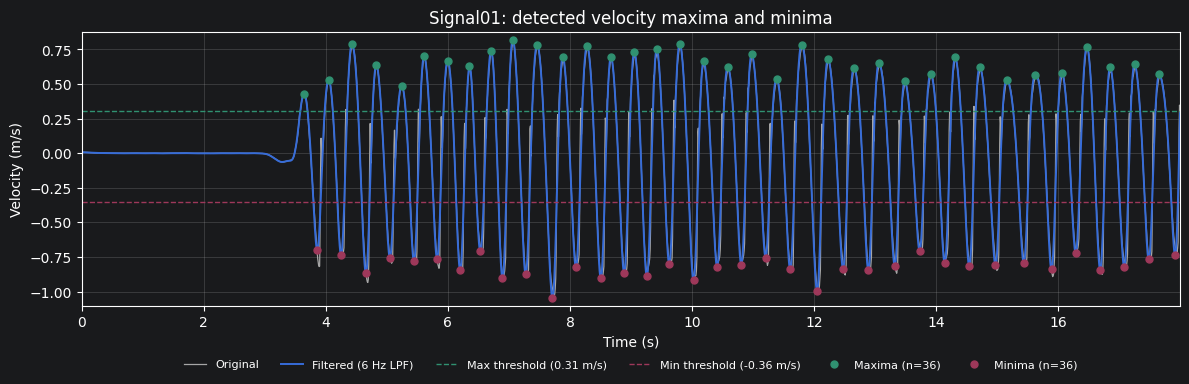

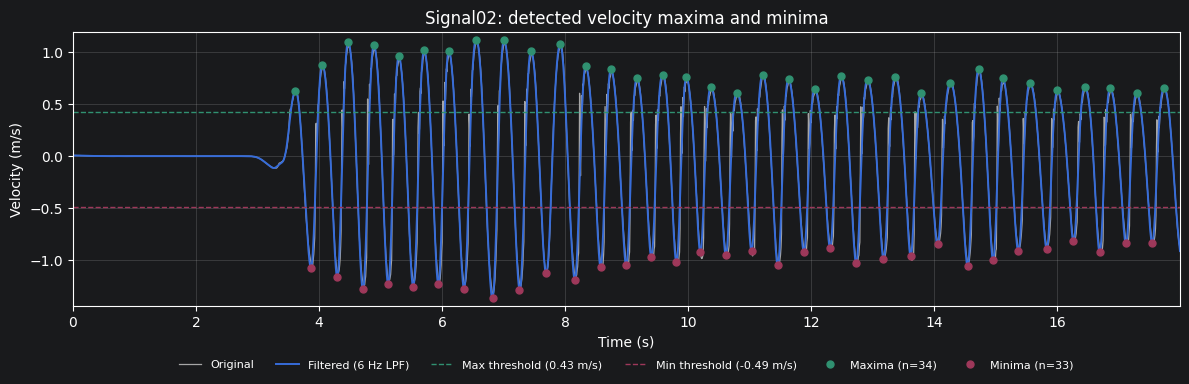

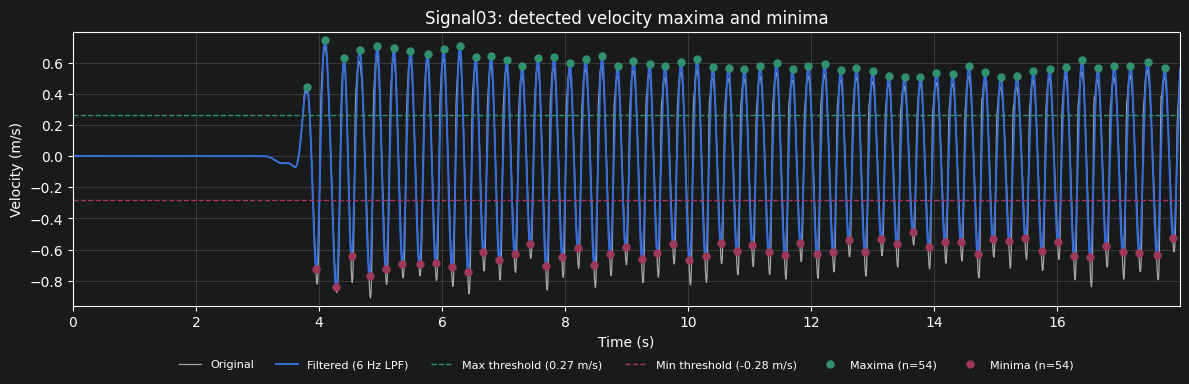

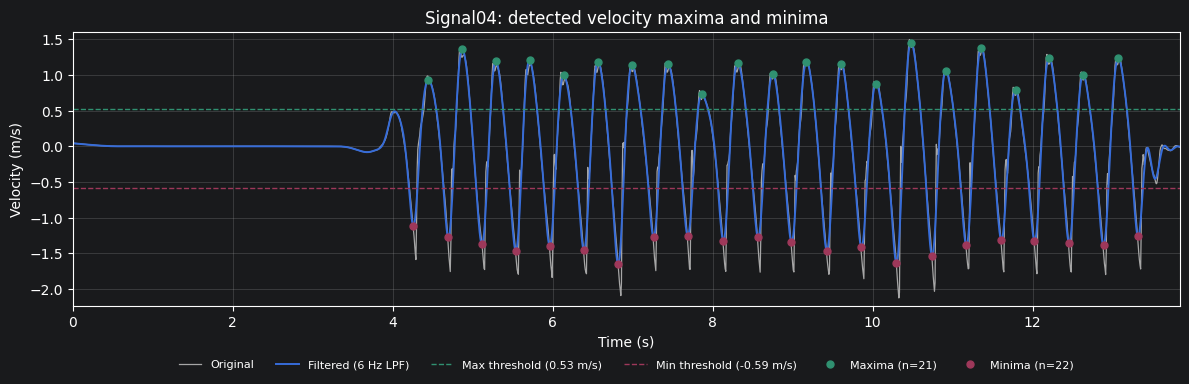

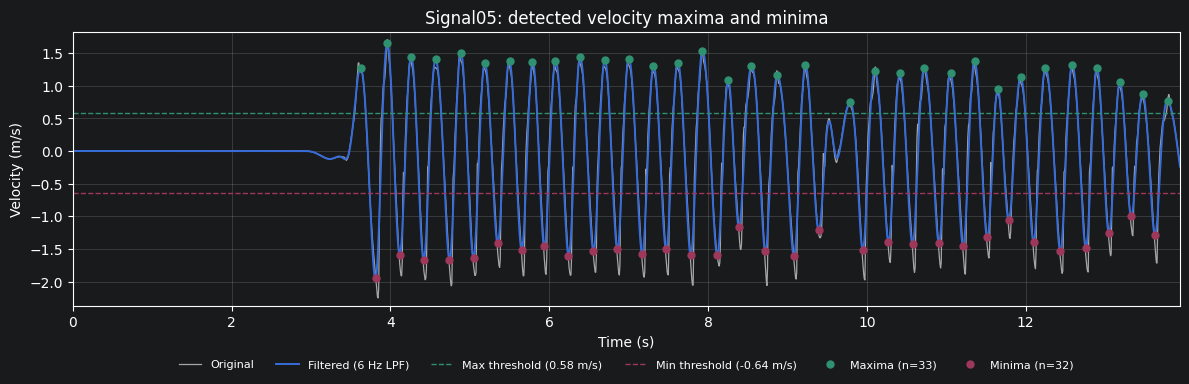

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
fs        = 128.0                  # sample rate (Hz)
data_dir  = os.path.join('.', 'Leg Agility')
files     = [f'Signal0{k}.txt' for k in range(1, 6)]

fc        = 6.0                    # low-pass cutoff (Hz)
order     = 4                      # Butterworth order (effective 8 with filtfilt)
thr_frac  = 0.4                    # threshold = 40% of the 99th / 1st percentile
min_sep_s = 0.20                   # minimum time between two maxima (or two minima), s

# ---------------------------------------------------------------
# Filter design: zero-phase low-pass Butterworth
# ---------------------------------------------------------------
b, a = signal.butter(order, fc / (fs / 2), btype='low')


def detect_extrema(x):
    """Filter x, then return the filtered signal, extrema indices and thresholds."""
    y = signal.filtfilt(b, a, x)                      # zero phase: no time shift of extrema
    thr_max = thr_frac * np.percentile(y, 99)         # positive threshold
    thr_min = thr_frac * np.percentile(y, 1)          # negative threshold
    dist = int(round(min_sep_s * fs))
    i_max, _ = signal.find_peaks( y, height= thr_max, distance=dist)
    i_min, _ = signal.find_peaks(-y, height=-thr_min, distance=dist)
    return y, i_max, i_min, thr_max, thr_min


# ---------------------------------------------------------------
# Run the algorithm on every recording
# ---------------------------------------------------------------
results = {}
for fname in files:
    x = np.loadtxt(os.path.join(data_dir, fname))
    t = np.arange(len(x)) / fs
    y, i_max, i_min, thr_max, thr_min = detect_extrema(x)
    results[fname] = dict(x=x, t=t, y=y, i_max=i_max, i_min=i_min,
                          thr_max=thr_max, thr_min=thr_min)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, x, color='0.65', lw=0.9, label='Original')
    ax.plot(t, y, color='C0',  lw=1.4, label=f'Filtered ({fc:g} Hz LPF)')
    ax.axhline(thr_max, color='C3', ls='--', lw=1, label=f'Max threshold ({thr_max:.2f} m/s)')
    ax.axhline(thr_min, color='C2', ls='--', lw=1, label=f'Min threshold ({thr_min:.2f} m/s)')
    ax.plot(t[i_max], y[i_max], 'o', color='C3', ms=5, label=f'Maxima (n={len(i_max)})')
    ax.plot(t[i_min], y[i_min], 'o', color='C2', ms=5, label=f'Minima (n={len(i_min)})')

    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    pad = 0.03 * (hi - lo)
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Velocity (m/s)')
    ax.set_title(f'{fname.removesuffix(".txt")}: detected velocity maxima and minima')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=6,
              fontsize=8, frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()